# Operasi Dasar Citra Digital: Perbandingan Gaussian Blur dan Median Filter

Mata kuliah: Pengolahan Citra Digital | Nama: Muhammad Sahal Anwar Hadi | NIM: 24260032

**Tujuan:** membandingkan dua metode *image filtering*, yaitu Gaussian Blur dan Median Filter, dalam mengurangi
salt-and-pepper noise, lalu menilainya secara visual dan dengan MSE/PSNR.

**Teori singkat**
- **Citra digital** adalah matriks piksel. Pada grayscale 8-bit tiap piksel bernilai 0 (hitam) sampai 255 (putih).
- **Noise** adalah gangguan acak pada nilai piksel. *Salt-and-pepper* mengubah piksel menjadi 255 (salt) atau 0 (pepper).
- **Filtering spasial** menghitung nilai baru piksel dari tetangganya dalam jendela kecil (*kernel*, ukuran ganjil: 3x3, 5x5, 7x7).
- **Gaussian Blur** (filter linear): rata-rata berbobot, piksel dekat pusat berbobot lebih besar. Noise ekstrem hanya diredam dan menyebar.
- **Median Filter** (non-linear): nilai dalam jendela diurutkan, lalu nilai tengah dipakai. Nilai ekstrem 0/255 terbuang.

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.13.0 | NumPy 2.2.6


In [29]:
NAMA_FILE_GAMBAR = "foto.jpg"  # ganti dengan nama gambar Anda

if not Path(NAMA_FILE_GAMBAR).exists():
    raise FileNotFoundError(
        f"'{NAMA_FILE_GAMBAR}' tidak ditemukan. Letakkan gambar JPG/PNG di folder yang sama dengan notebook."
    )

gambar_bgr = cv2.imread(NAMA_FILE_GAMBAR)
if gambar_bgr is None:  # file ada tetapi bukan gambar valid
    raise ValueError(
        f"'{NAMA_FILE_GAMBAR}' gagal dibaca. Pakai file JPG/PNG yang valid."
    )

print("Memakai gambar:", NAMA_FILE_GAMBAR)
print("Ukuran:", gambar_bgr.shape, "| tipe:", gambar_bgr.dtype)

Memakai gambar: foto.jpg
Ukuran: (4064, 3048, 3) | tipe: uint8


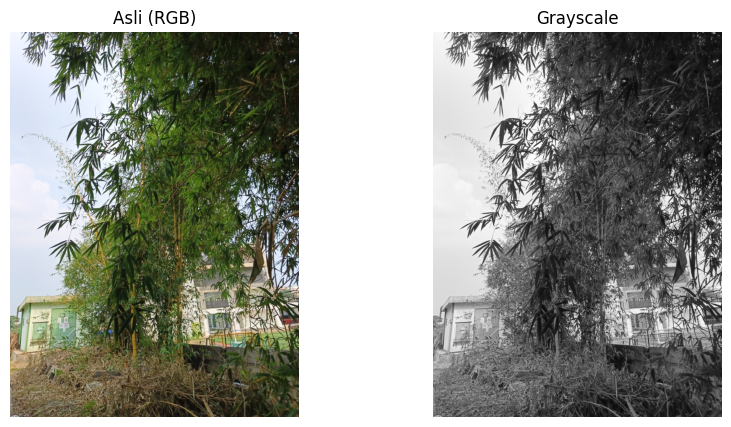

In [30]:
gambar_rgb = cv2.cvtColor(gambar_bgr, cv2.COLOR_BGR2RGB)    # OpenCV = BGR, Matplotlib = RGB
gambar_gray = cv2.cvtColor(gambar_bgr, cv2.COLOR_BGR2GRAY)  # referensi bersih untuk evaluasi

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(gambar_rgb);                              ax[0].set_title("Asli (RGB)")
ax[1].imshow(gambar_gray, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Grayscale")
for a in ax: a.axis("off")
plt.show()

In [31]:
TINGKAT_NOISE = 0.05   # 0.05 = 5% piksel terkena noise
SEED_ACAK = 42         # seed tetap agar hasil bisa diulang


def tambah_salt_pepper(citra, tingkat, seed):
    hasil = citra.copy()                           # salinan, citra asli tidak berubah
    acak = np.random.default_rng(seed).random(citra.shape)
    hasil[acak < tingkat / 2] = 0                  # pepper (hitam)
    hasil[acak > 1 - tingkat / 2] = 255            # salt (putih)
    return hasil


gray_noise = tambah_salt_pepper(gambar_gray, TINGKAT_NOISE, SEED_ACAK)
print(f"Piksel berubah: {np.mean(gray_noise != gambar_gray) * 100:.2f}%")

Piksel berubah: 5.01%


**Metode filter.** Kedua filter menerima citra ber-noise yang sama dan ukuran kernel yang sama agar perbandingan adil. Kernel harus ganjil.

In [32]:
UKURAN_KERNEL = 5   # ganjil: 3, 5, 7, ...

# GaussianBlur(citra, (lebar, tinggi) kernel, sigmaX)
#   kernel harus ganjil; sigmaX=0 -> sigma dihitung otomatis dari ukuran kernel
#   makin besar kernel/sigma, makin buram
hasil_gaussian = cv2.GaussianBlur(gray_noise, (UKURAN_KERNEL, UKURAN_KERNEL), 0)

# medianBlur(citra, ukuran) : ukuran satu angka ganjil > 1 (5 = jendela 5x5)
#   tiap piksel diganti median dari 25 nilai di sekitarnya
hasil_median = cv2.medianBlur(gray_noise, UKURAN_KERNEL)

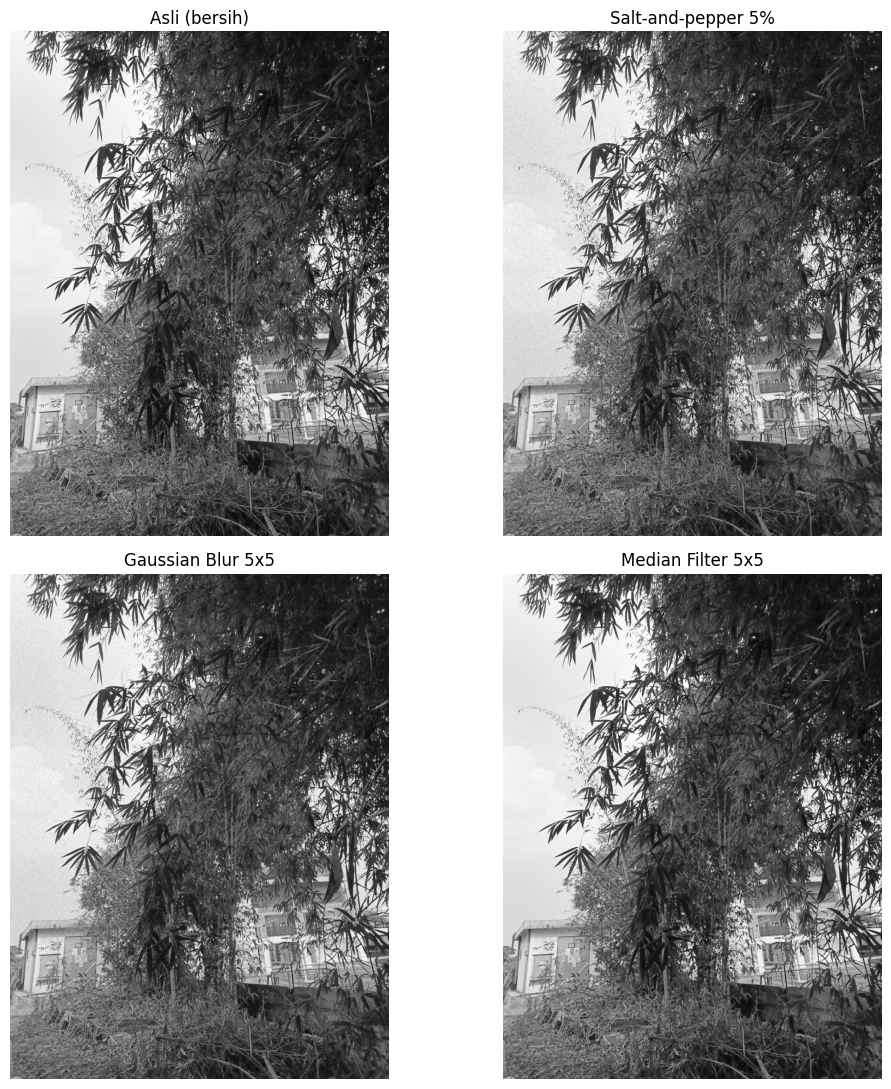

In [33]:
fig, ax = plt.subplots(2, 2, figsize=(11, 11))
daftar = [(gambar_gray, "Asli (bersih)"),
          (gray_noise, f"Salt-and-pepper {TINGKAT_NOISE*100:.0f}%"),
          (hasil_gaussian, f"Gaussian Blur {UKURAN_KERNEL}x{UKURAN_KERNEL}"),
          (hasil_median, f"Median Filter {UKURAN_KERNEL}x{UKURAN_KERNEL}")]
for a, (citra, judul) in zip(ax.flatten(), daftar):
    a.imshow(citra, cmap="gray", vmin=0, vmax=255)
    a.set_title(judul)
    a.axis("off")
plt.tight_layout()
plt.show()

**Evaluasi.** MSE = rata-rata kuadrat selisih piksel (makin kecil makin mirip). PSNR = $10\log_{10}(255^2/\text{MSE})$ dalam dB
(makin besar makin mirip). Keduanya dibandingkan dengan grayscale asli yang bersih. Keduanya tidak selalu sejalan dengan kesan visual.

In [34]:
def hitung_mse(referensi, uji):
    selisih = referensi.astype(np.float64) - uji.astype(np.float64)  # float agar tidak overflow uint8
    return np.mean(selisih ** 2)


def hitung_psnr(referensi, uji):
    mse = hitung_mse(referensi, uji)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


tabel = pd.DataFrame({
    "Citra": ["Ber-noise", "Gaussian Blur", "Median Filter"],
    "MSE": [hitung_mse(gambar_gray, c) for c in (gray_noise, hasil_gaussian, hasil_median)],
    "PSNR (dB)": [hitung_psnr(gambar_gray, c) for c in (gray_noise, hasil_gaussian, hasil_median)],
}).round(2)
tabel

,Citra,MSE,PSNR (dB)
0,Ber-noise,1120.36,17.64
1,Gaussian Blur,160.53,26.08
2,Median Filter,78.12,29.20


**Eksperimen kernel** 3x3, 5x5, dan 7x7 pada citra ber-noise yang sama.

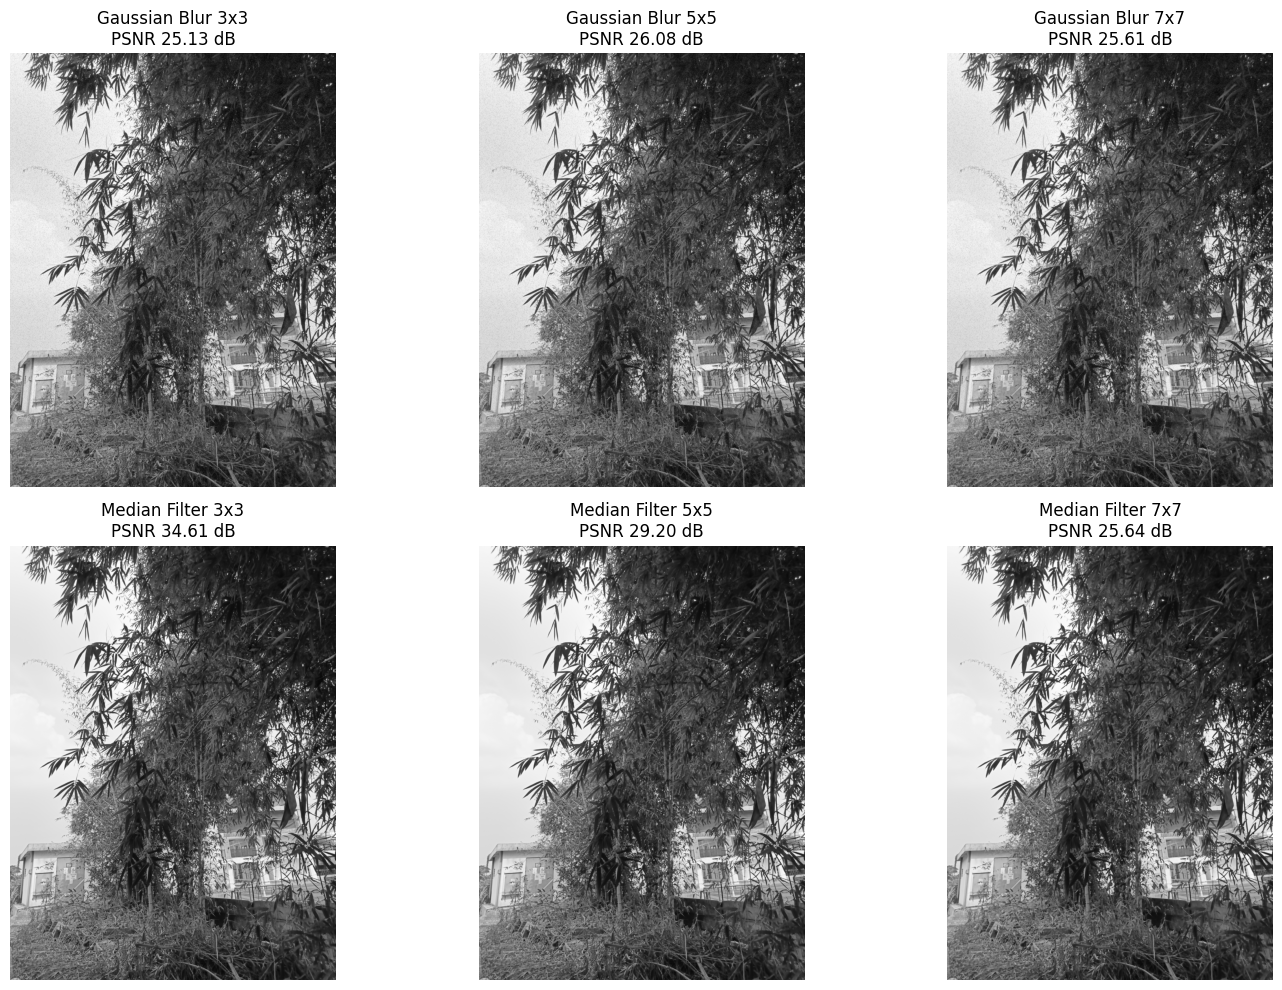

,Metode,Kernel,MSE,PSNR (dB)
0,Gaussian Blur,3x3,199.69,25.13
1,Median Filter,3x3,22.52,34.61
2,Gaussian Blur,5x5,160.53,26.08
3,Median Filter,5x5,78.12,29.20
4,Gaussian Blur,7x7,178.61,25.61
5,Median Filter,7x7,177.58,25.64


In [35]:
daftar_kernel = [3, 5, 7]
hasil_uji = {}
baris = []
for k in daftar_kernel:
    hasil_uji[("Gaussian Blur", k)] = cv2.GaussianBlur(gray_noise, (k, k), 0)
    hasil_uji[("Median Filter", k)] = cv2.medianBlur(gray_noise, k)

for (metode, k), citra in hasil_uji.items():
    baris.append({"Metode": metode, "Kernel": f"{k}x{k}",
                  "MSE": hitung_mse(gambar_gray, citra),
                  "PSNR (dB)": hitung_psnr(gambar_gray, citra)})
tabel_kernel = pd.DataFrame(baris).round(2)

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for kolom, k in enumerate(daftar_kernel):
    for r, metode in enumerate(["Gaussian Blur", "Median Filter"]):
        citra = hasil_uji[(metode, k)]
        ax[r, kolom].imshow(citra, cmap="gray", vmin=0, vmax=255)
        ax[r, kolom].set_title(f"{metode} {k}x{k}\nPSNR {hitung_psnr(gambar_gray, citra):.2f} dB")
        ax[r, kolom].axis("off")
plt.tight_layout()
plt.show()
tabel_kernel

**Analisis.** Kalimat di bawah dibuat otomatis dari angka yang dihitung program, jadi selalu sesuai gambar dan noise yang dipakai. Bandingkan juga dengan gambar di atas: perhatikan sisa bintik noise, tepi objek, dan detail halus pada foto.

In [36]:
psnr_noise = hitung_psnr(gambar_gray, gray_noise)
print(f"PSNR tanpa filter: {psnr_noise:.2f} dB\n")

for k in daftar_kernel:
    bagian = tabel_kernel[tabel_kernel["Kernel"] == f"{k}x{k}"]
    unggul = bagian.loc[bagian["PSNR (dB)"].idxmax(), "Metode"]
    print(f"Kernel {k}x{k}: PSNR tertinggi = {unggul}")

print()
for metode in ["Gaussian Blur", "Median Filter"]:
    bagian = tabel_kernel[tabel_kernel["Metode"] == metode]
    terbaik = bagian.loc[bagian["PSNR (dB)"].idxmax()]
    print(f"{metode}: kernel terbaik = {terbaik['Kernel']} ({terbaik['PSNR (dB)']} dB)")
    print(f"   PSNR kernel terkecil -> terbesar: {bagian['PSNR (dB)'].tolist()}")

PSNR tanpa filter: 17.64 dB

Kernel 3x3: PSNR tertinggi = Median Filter
Kernel 5x5: PSNR tertinggi = Median Filter
Kernel 7x7: PSNR tertinggi = Median Filter

Gaussian Blur: kernel terbaik = 5x5 (26.08 dB)
   PSNR kernel terkecil -> terbesar: [25.13, 26.08, 25.61]
Median Filter: kernel terbaik = 3x3 (34.61 dB)
   PSNR kernel terkecil -> terbesar: [34.61, 29.2, 25.64]


**Cara membaca analisis.** Median Filter secara teori unggul pada salt-and-pepper noise karena nilai ekstrem terbuang,
sedangkan Gaussian Blur hanya menyebarkannya. Pengaruh kernel: makin besar, noise makin berkurang tetapi detail
(tepi objek dan tekstur halus) makin hilang atau buram. Jika PSNR turun saat kernel membesar, itu tanda detail yang hilang
lebih besar pengaruhnya daripada noise yang terhapus. Hasil bisa berbeda untuk gambar, tingkat noise, atau seed lain.
Keterbatasan: satu gambar, satu jenis noise, tanpa metrik persepsi seperti SSIM.

**Kesimpulan.** Gaussian Blur dan Median Filter sudah diimplementasikan dengan OpenCV dan dibandingkan secara adil pada
citra, noise, dan kernel yang sama. Metode dan kernel terbaik untuk percobaan ini ada pada keluaran cell analisis di atas.
Filter harus dipilih sesuai jenis noise, dan ukuran kernel adalah kompromi antara pengurangan noise dan kelestarian detail.
